# [Lab Session 4](deconvolution.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')
plt.show()

<Figure size 640x480 with 1 Axes>

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [4]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

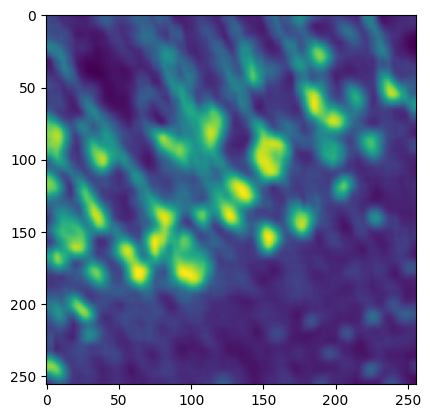

In [5]:
cellpsf = conv(img, psf, mode = 'same', boundary = 'symm')
plt.imshow(cellpsf)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

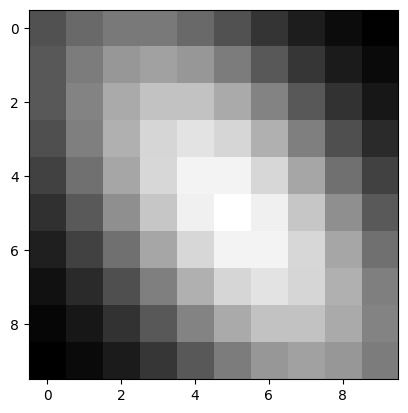

In [33]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

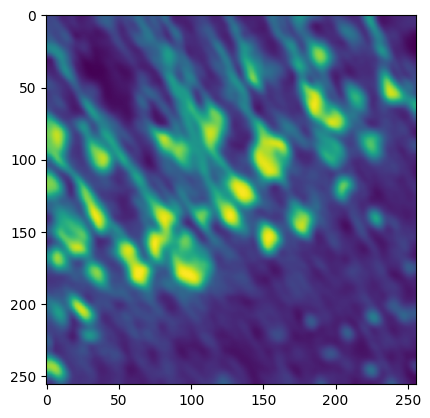

In [7]:
gpfs = create_psf(psf_size)
img_gpfs = conv(img, gpfs, mode = "same", boundary = "symm")
plt.imshow(img_gpfs)

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [8]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)

    flip = np.flip(psf)
    for i in range(n_iterations):
        blurr = conv(img_deconv, psf, mode = 'same', boundary = 'symm')
        Bruch = image / blurr
        korrekt = conv(Bruch, flip, mode = 'same', boundary = 'symm')
        img_deconv = img_deconv * korrekt
        
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [9]:
Rl = richardson_lucy_deconvolution(cellpsf, psf, 300)

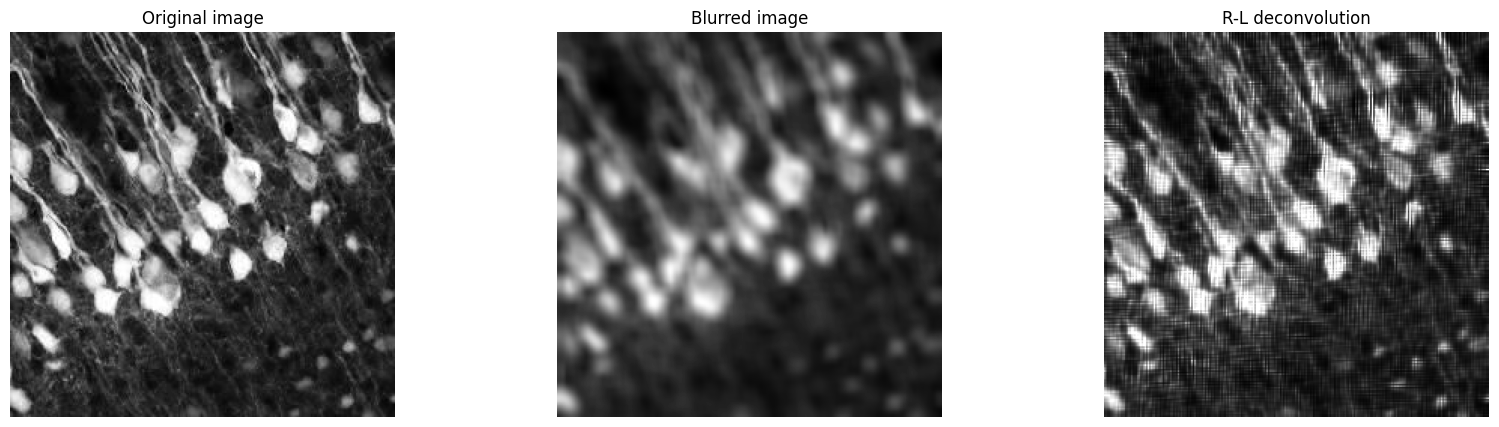

In [10]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(cellpsf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(Rl, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [11]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

In [12]:
noise_img = cellpsf + noise
noise_img = noise_img.clip(0,1)


In [13]:
Rl_noise = richardson_lucy_deconvolution(noise_img, psf, 20)

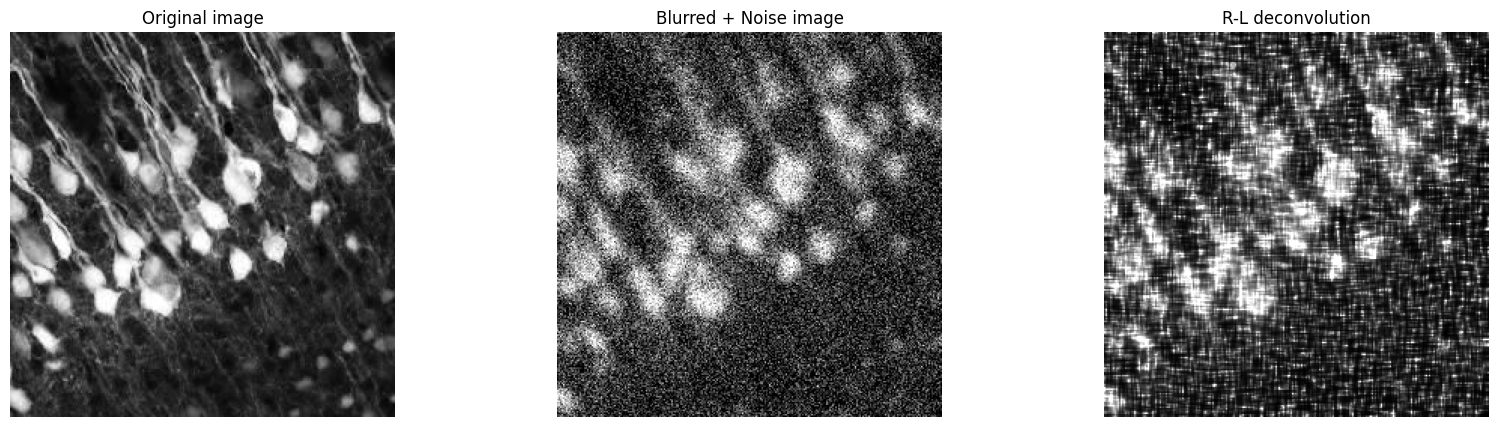

In [14]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(noise_img, 'gray')
plt.title('Blurred + Noise image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(Rl_noise, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

In [15]:
wiener1 = wiener(cellpsf, gpfs, balance= 2, clip = True)


In [16]:
Rl = richardson_lucy_deconvolution(cellpsf, psf, 300)

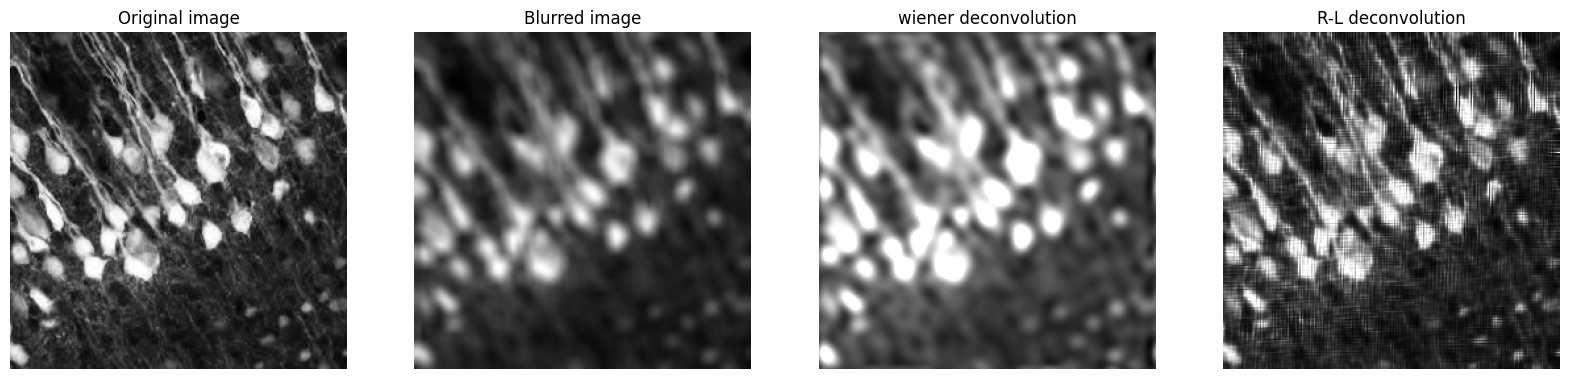

In [17]:
plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(cellpsf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(wiener1, 'gray')
plt.title('wiener deconvolution')
plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(Rl, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

In [18]:
psf_size1 = 5
psf1 = np.ones((psf_size1, psf_size)) / psf_size ** 2

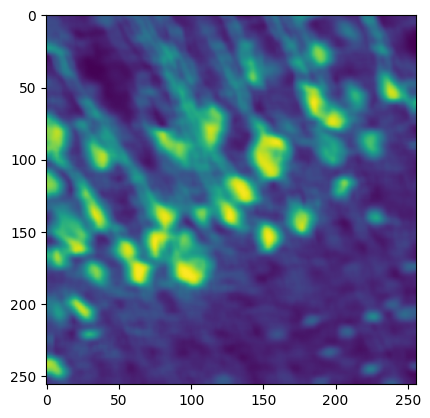

In [19]:
cellpsf1 = conv(img, psf1, mode = 'same', boundary = 'symm')
plt.imshow(cellpsf1)

In [23]:
Rl1 = richardson_lucy_deconvolution(cellpsf1, psf1, 200)

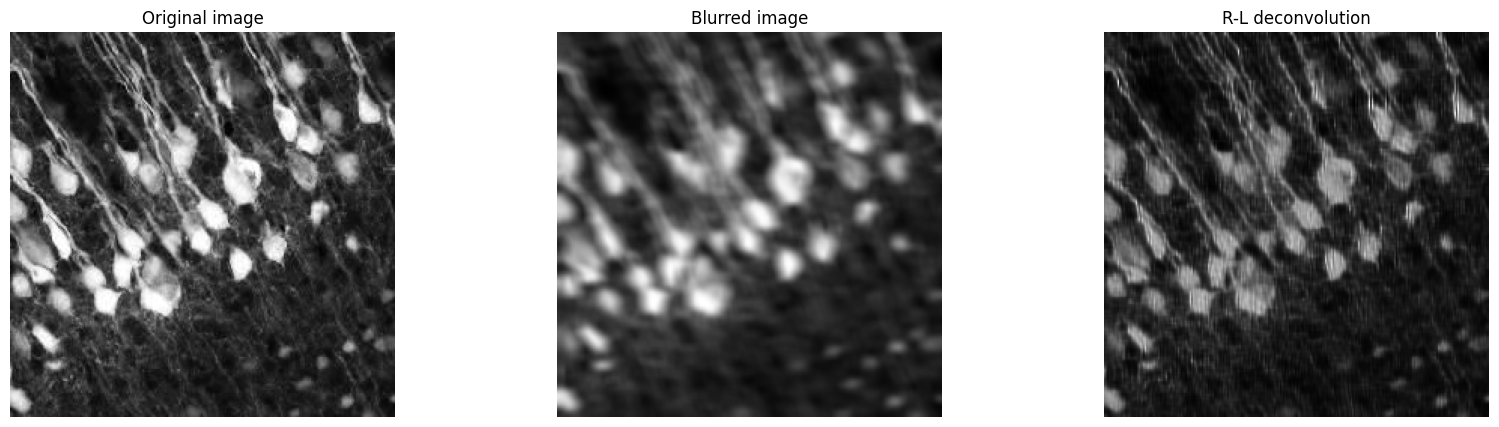

In [24]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(cellpsf1, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(Rl1, 'gray')
plt.title('R-L deconvolution')
plt.show()

In [26]:
noise_img1 = cellpsf1 + noise
noise_img1 = noise_img.clip(0,1)

In [47]:
Rl_noise1 = richardson_lucy_deconvolution(noise_img1, psf1, 50)

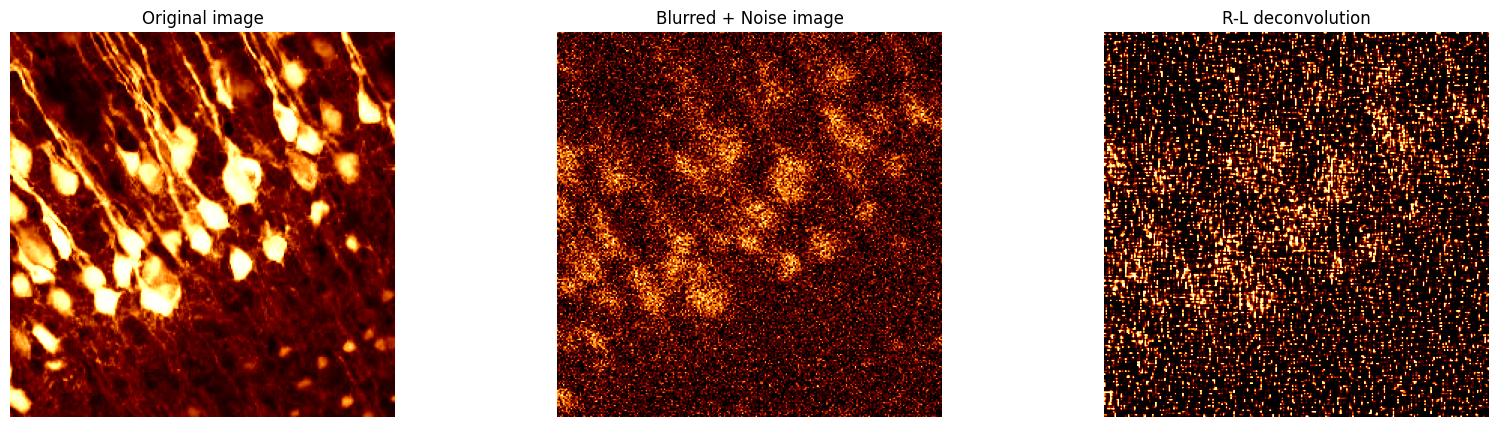

In [53]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'afmhot')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(noise_img1, 'afmhot')
plt.title('Blurred + Noise image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(Rl_noise1, 'afmhot')
plt.title('R-L deconvolution')
plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

Text(0.5, 1.0, 'Img_gpfs')

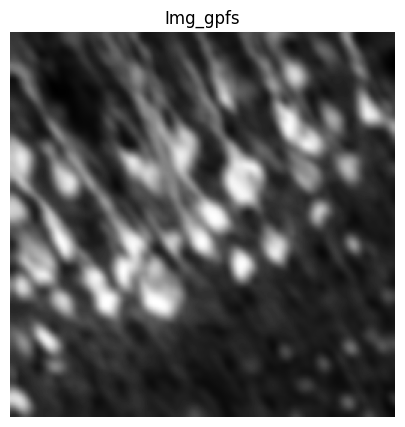

In [30]:
gaussuniform = richardson_lucy_deconvolution(img_gpfs, psf, 300)
plt.figure(figsize=(20,5))

plt.axis('off')
plt.imshow(img_gpfs, 'gray')
plt.title('Img_gpfs')

Text(0.5, 1.0, 'psf Gauss')

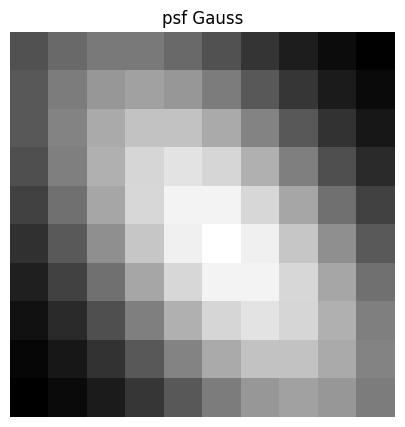

In [38]:
psf_gauss = create_psf(psf.shape[0])
plt.figure(figsize=(20,5))

plt.axis('off')
plt.imshow(psf_gauss, 'gray')
plt.title('psf Gauss')

Text(0.5, 1.0, 'Uniform Blurred')

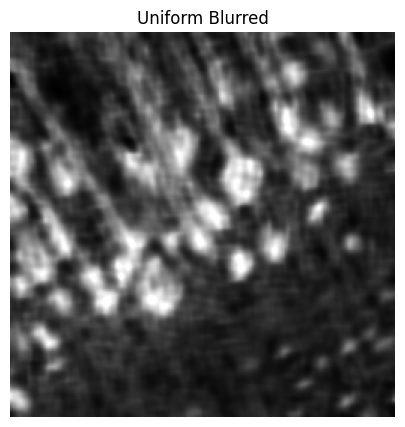

In [55]:
uniformblurred = richardson_lucy_deconvolution(cellpsf, psf_gauss, 50)
plt.figure(figsize=(20,5))

plt.axis('off')
plt.imshow(uniformblurred, 'gray')
plt.title('Uniform Blurred')